# PD Scorecard in R

Many credit-risk teams build their scorecards in R, with packages that turn the whole workflow, from variable selection to the points table, into a few readable steps. This notebook follows that workflow end to end on 30,000 credit-card clients and finishes with the approval cutoff a credit committee would sign.

**What it does.** It filters variables by information value, bins them with monotonic weight of evidence, fits a logistic regression on the WoE values and scales it to points.

It then validates the scorecard on a hold-out sample with Gini, KS, calibration and population stability, and sets an approval cutoff from expected losses.

**Data.** The UCI *Default of Credit Card Clients* dataset (Yeh & Lien, 2009): 30,000 Taiwanese card holders, six months of repayment status, bill and payment amounts, and default in the following month. It is downloaded from the UCI archive, or from UCI's mirror on Kaggle if the archive is unreachable.

**Methods.** The `scorecard` package (variable filter, `woebin` binning with manual monotonic adjustments, `scorecard` points, `perf_eva`, `perf_psi`), logistic regression with stepwise AIC selection, `pROC` for the ROC and the DeLong confidence interval of the AUC, score-band calibration and an expected-loss cutoff.

**Key output.** The IV ranking, WoE tables, model coefficients, the points table, train and test Gini and KS, PSI, calibration by score band, and the approval cutoff with its approval rate and expected loss.

## 1. Why a WoE scorecard

Scorecards are still the standard for retail and SME PD models because every step can be explained to a credit committee and a regulator:

- **Weight of evidence (WoE)** turns each variable into bins whose log-odds of good vs bad are monotonic: $\mathrm{WoE}_b=\ln\frac{\%\text{good}_b}{\%\text{bad}_b}$.
- **Information value (IV)**, $\sum_b(\%\text{good}_b-\%\text{bad}_b)\,\mathrm{WoE}_b$, ranks predictive power: below 0.02 useless, 0.02–0.1 weak, 0.1–0.3 medium, above 0.3 strong.
- A **logistic regression on WoE** gives coefficients that should all be positive in sign (WoE already orients each variable), and the score is linear in points: each bin adds or subtracts a fixed number of points.

This notebook shows the R workflow that many risk teams use.

## 2. Setup

In [1]:
# --- Packages (install once with `Rscript install_packages.R` from the repo
# root)
suppressPackageStartupMessages({
  library(tidyverse)
  library(scales)
  library(patchwork)
  library(plotly)
  library(htmlwidgets)
  library(jsonlite)
})
options(warn = 1, dplyr.summarise.inform = FALSE, repr.plot.width = 14,
        repr.plot.height = 5, repr.plot.res = 110)
# plain-text tables in the notebook (no ANSI colour codes)
options(crayon.enabled = FALSE, cli.num_colors = 1)

# --- Folders and credentials
PROJECT_DIR <- getwd()
DATA_DIR <- file.path(PROJECT_DIR,
                      "data"); OUT_DIR <- file.path(PROJECT_DIR, "outputs")
dir.create(DATA_DIR,
           showWarnings = FALSE); dir.create(OUT_DIR, showWarnings = FALSE)
# look for .env in this folder and its parents (like python-dotenv)
find_env <- function(start = getwd()) {
  d <- normalizePath(start)
  repeat {
    f <- file.path(d, ".env")
    if (file.exists(f)) return(f)
    parent <- dirname(d)
    if (parent == d) return(NA_character_)
    d <- parent
  }
}
env_file <- find_env()
# tolerate a missing final newline
if (!is.na(env_file)) suppressWarnings(dotenv::load_dot_env(env_file))

# --- Cache helper: every download is stored in data/ and reused for 12 hours
cached <- function(name, fetch, max_age_hours = 12) {
  path <- file.path(DATA_DIR, paste0(name, ".rds"))
  if (file.exists(path) &&
      difftime(Sys.time(), file.mtime(path),
               units = "hours") < max_age_hours) return(readRDS(path))
  out <- tryCatch(fetch(), error = function(e) {
    if (file.exists(path)) {
      message(name, ": download failed (", conditionMessage(e),
              "); using cached copy"); return(readRDS(path))
    }
    stop(e)
  })
  saveRDS(out, path)
  out
}

# --- Chart style (consistent palette across all charts)
PALETTE <- c("#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300",
             "#6250d6", "#e34948")
INK <- "#0b0b0b"; INK_2 <- "#52514e"; GRID <- "#e4e3df"; SURFACE <- "#fcfcfb"
STATUS <- c(green = "#1baf7a", amber = "#eda100", red = "#e34948")
theme_risk <- function() {
  theme_minimal(base_size = 11) +
    theme(
      plot.background = element_rect(fill = SURFACE, colour = NA),
        panel.background = element_rect(fill = SURFACE, colour = NA),
      panel.grid.major = element_line(colour = GRID),
        panel.grid.minor = element_blank(),
      plot.title = element_text(face = "bold", colour = INK, size = 12),
        plot.title.position = "plot",
      axis.text = element_text(colour = INK_2),
        axis.title = element_text(colour = INK_2),
      legend.position = "top", legend.title = element_blank()
    )
}
theme_set(theme_risk())
save_fig <- function(p, name, width = 14,
                     height = 5) ggsave(file.path(
                         OUT_DIR, paste0(name, ".png")),
                                        p, width = width, height = height,
                                        dpi = 150, bg = SURFACE)

# Interactive dashboard as a single HTML file that loads plotly.js from a CDN
# (no pandoc needed)
save_plotly_html <- function(widget, name, title) {
  b <- plotly_build(widget)$x
  if (is.null(b$layout$height)) b$layout$height <- 900
  html <- sprintf(
    '<!doctype html><html><head><meta charset="utf-8"><title>%s</title>
<script src="https://cdn.plot.ly/plotly-2.35.2.min.js"></script></head>
<body style="background:%s;margin:0"><div id="dash" style="width:100%%;height:95vh"></div>
<script>var fig=%s;Plotly.newPlot("dash",fig.data,fig.layout,{responsive:true});</script></body></html>',
    title, SURFACE,
      toJSON(list(data = b$data, layout = b$layout), auto_unbox = TRUE,
             null = "null", na = "null", force = TRUE, digits = NA)
  )
  writeLines(html, file.path(OUT_DIR, paste0(name, ".html")))
  message("Dashboard saved: outputs/", name, ".html")
}

suppressPackageStartupMessages({
  library(scorecard)
  library(pROC)
  library(readxl)
})
UCI_URL <- "https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip"
SEED <- 42
# 600 points at good:bad odds of 19:1, 50 points to double the odds
PDO <- 50; POINTS0 <- 600; ODDS0 <- 1 / 19
LGD <- 0.75 # unsecured card loss given default
MARGIN <- 0.04 # annual net revenue on the limit for a good client
set.seed(SEED)
cat(sprintf("R %s · scorecard %s · pROC %s · run on %s\n", getRversion(),
            packageVersion("scorecard"), packageVersion("pROC"), Sys.Date()))

R 4.3.3 · scorecard 0.4.6 · pROC 1.18.5 · run on 2026-10-19


## 3. Data

In [2]:
fetch_uci <- function() {
  zip <- tempfile(fileext = ".zip")
  download.file(UCI_URL, zip, mode = "wb", quiet = TRUE)
  xls <- unzip(zip, exdir = tempdir())
  read_excel(xls[grepl("\\.xls$", xls)][1], skip = 1)
}
# same data, mirrored by UCI on Kaggle; needs KAGGLE_API_TOKEN in .env
fetch_kaggle <- function() {
  tok <- Sys.getenv("KAGGLE_API_TOKEN")
  if (tok == "") stop("UCI unreachable and KAGGLE_API_TOKEN not set")
  zip <- tempfile(fileext = ".zip")
  resp <- httr2::request("https://www.kaggle.com/api/v1/datasets/download/uciml/default-of-credit-card-clients-dataset") %>%
    httr2::req_auth_bearer_token(tok) %>%
    httr2::req_perform(path = zip)
  read_csv(unzip(zip, exdir = tempdir())[1], show_col_types = FALSE)
}
raw <- cached("uci_taiwan_default", function() {
  tryCatch(fetch_uci(), error = function(e) {
    message("UCI archive unreachable (", conditionMessage(e),
            "); using the UCI mirror on Kaggle"); fetch_kaggle()
  })
}, max_age_hours = 24 * 365)
names(raw) <- sub("^default[ .]payment[ .]next[ .]month$", "default",
                  names(raw))
df <- raw %>%
  rename(PAY_1 = PAY_0) %>%
  select(-ID) %>%
  mutate(
    SEX = factor(SEX, 1:2, c("male", "female")),
    EDUCATION = factor(case_when(EDUCATION == 1 ~ "graduate",
                                 EDUCATION == 2 ~ "university",
                                 EDUCATION == 3 ~ "high school",
                                 TRUE ~ "other")),
    MARRIAGE = factor(case_when(MARRIAGE == 1 ~ "married",
                                MARRIAGE == 2 ~ "single", TRUE ~ "other")),
    # behavioural features commonly added to this dataset
    util_1 = BILL_AMT1 / pmax(LIMIT_BAL, 1),
    pay_ratio_1 = ifelse(BILL_AMT1 > 0, PAY_AMT1 / BILL_AMT1, 1),
    months_delinquent = rowSums(across(PAY_1:PAY_6, ~ .x > 0)),
    max_delinquency = pmax(PAY_1, PAY_2, PAY_3, PAY_4, PAY_5, PAY_6)
  )
cat(sprintf("%s clients · default rate %.1f%% · %d candidate variables\n",
            format(nrow(df), big.mark = ","), mean(df$default) * 100,
            ncol(df) - 1))
split <- split_df(df, y = "default", ratios = c(0.7, 0.3), seed = SEED)
train <- split$train; test <- split$test
cat(sprintf(
  "train %s (%.1f%% default) · test %s (%.1f%% default)\n",
    format(nrow(train), big.mark = ","), mean(train$default) * 100,
  format(nrow(test), big.mark = ","), mean(test$default) * 100
))

30,000 clients · default rate 22.1% · 27 candidate variables


train 21,005 (21.9% default) · test 8,995 (22.6% default)


## 4. Variable selection and WoE binning

`var_filter` drops variables with IV below 0.02, more than 95% missing or 95% identical values. `woebin` then bins the survivors with a decision-tree method. Binning is reviewed by hand where the WoE is not monotonic, which is the standard modelling-standards requirement (for example the repayment-status variables, whose codes −2, −1 and 0 all mean "no delinquency").

In [3]:
train_f <- as.data.frame(var_filter(train,
  y = "default", iv_limit = 0.02,
  missing_limit = 0.95,
  identical_limit = 0.95, var_kp = NULL
))
iv_all <- iv(train, y = "default") %>% arrange(desc(info_value))
bins <- woebin(train_f,
  y = "default", method = "tree", stop_limit = 0.05,
  count_distr_limit = 0.05, bin_num_limit = 6, print_info = FALSE
)
# Manual review: merge the "no delinquency" codes of the repayment-status
# variables, and force monotonic bins elsewhere
# bins: no delinquency (−2, −1, 0) | 1 month | 2+ months
pay_breaks <- setNames(rep(list(c(1, 2)), 6), paste0("PAY_", 1:6))
monotonic_check <- function(b) {
  w <- b$woe[b$bin != "missing"]; all(diff(w) >= 0) || all(diff(w) <= 0)
}
non_mono <- names(bins)[!sapply(bins, monotonic_check)]
breaks_adj <- pay_breaks[names(pay_breaks) %in% names(bins)]
bins <- woebin(train_f,
  y = "default", method = "tree", breaks_list = breaks_adj, stop_limit = 0.05,
  count_distr_limit = 0.05,
  bin_num_limit = 6, print_info = FALSE
)
still_non_mono <- names(bins)[!sapply(bins, monotonic_check)]
for (v in still_non_mono) { # fall back to fewer bins until monotonic
  for (k in 5:2) {
    b <- woebin(as.data.frame(train_f)[, c(v, "default")],
      y = "default",
      method = "tree", bin_num_limit = k, print_info = FALSE
    )[[1]]
    if (monotonic_check(b)) {
      bins[[v]] <- b; break
    }
  }
}
cat(sprintf(
  "Kept %d of %d variables (IV ≥ 0.02); %d needed monotonic re-binning\n",
  ncol(train_f) - 1, ncol(train) - 1,
  length(unique(c(non_mono, still_non_mono)))
))
iv_tab <- map_dfr(
  bins,
  ~ tibble(
    variable = .x$variable[1], IV = .x$total_iv[1],
    bins = nrow(.x)
  )
) %>%
  arrange(desc(IV)) %>%
  mutate(strength = cut(
    IV, c(-Inf, 0.02, 0.1, 0.3, 0.5, Inf),
    c(
      "useless", "weak", "medium", "strong",
      "suspicious (>0.5)"
    )
  ))
iv_tab %>% mutate(IV = round(IV, 3))

ℹ Filtering variables via missing_rate, identical_rate, info_value ...


✔ 2 variables are removed via info_value
✔ Variable filtering on 21005 rows and 27 columns in 00:00:01
✔ 2 variables are removed in total


Warning message in check_breaks_list(breaks_list, xs):
“There are 19 x variables that are not specified in breaks_list, and instead are using optimal binning.”


Kept 25 of 27 variables (IV ≥ 0.02); 17 needed monotonic re-binning


variable,IV,bins,strength
<chr>,<dbl>,<int>,<fct>
PAY_1,0.919,3,suspicious (>0.5)
months_delinquent,0.887,4,suspicious (>0.5)
max_delinquency,0.786,3,suspicious (>0.5)
PAY_2,0.568,3,suspicious (>0.5)
PAY_3,0.413,3,strong
PAY_4,0.359,3,strong
PAY_5,0.341,2,strong
PAY_6,0.299,2,medium
PAY_AMT1,0.162,5,medium


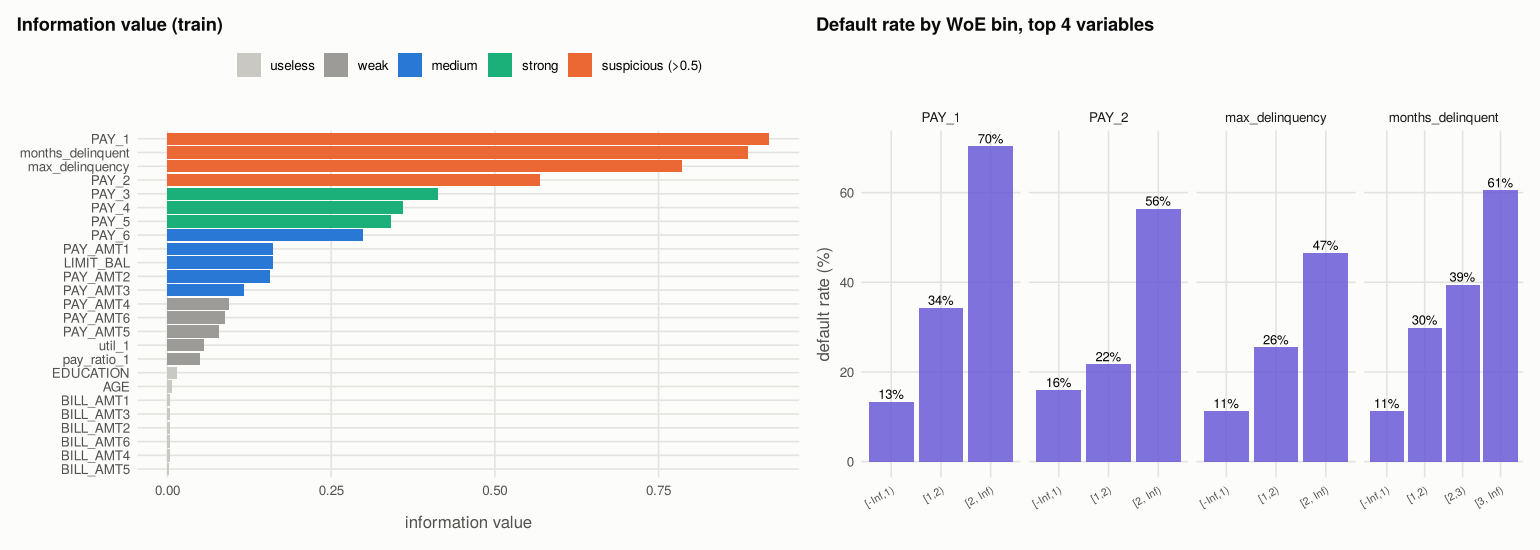

In [4]:
# --- Chart 1: IV ranking and WoE of the strongest variables
p_iv <- ggplot(iv_tab, aes(reorder(variable, IV), IV, fill = strength)) +
  geom_col() +
  coord_flip() +
  scale_fill_manual(values = c(
    useless = "#c9c8c3", weak = "#9c9b97",
    medium = PALETTE[1], strong = PALETTE[3],
    `suspicious (>0.5)` = PALETTE[2]
  )) +
  labs(x = NULL, y = "information value", title = "Information value (train)")
top4 <- head(iv_tab$variable, 4)
woe_df <- map_dfr(top4, ~ bins[[.x]] %>%
  transmute(variable,
    bin = factor(bin, levels = bin), woe,
    bad_rate = posprob, count_distr
  ))
p_woe <- ggplot(woe_df, aes(bin, bad_rate * 100)) +
  geom_col(fill = PALETTE[7], alpha = 0.8) +
  geom_text(aes(label = sprintf("%.0f%%", bad_rate * 100)),
    vjust = -0.3,
    size = 3
  ) +
  facet_wrap(~variable, scales = "free_x", nrow = 1) +
  labs(
    x = NULL, y = "default rate (%)",
    title = "Default rate by WoE bin, top 4 variables"
  ) +
  theme(axis.text.x = element_text(angle = 30, hjust = 1, size = 7))
fig1 <- p_iv | p_woe
save_fig(fig1, "01_iv_and_woe", width = 16, height = 5)
print(fig1)

## 5. Logistic regression on WoE and the points table

All selected variables enter as WoE values, and stepwise AIC selection removes those that add nothing given the others. A WoE model should have **positive coefficients only**: a negative one means multicollinearity is flipping a variable's effect, and that variable is dropped. Points are then scaled so that 600 points correspond to odds of 19:1 and 50 points double the odds.

In [5]:
train_woe <- woebin_ply(train_f, bins, print_info = FALSE)
test_woe <- woebin_ply(test %>% select(any_of(names(train_f))), bins,
  print_info = FALSE
)
full <- glm(default ~ ., family = binomial(), data = train_woe)
step_m <- step(full, direction = "both", trace = 0)
coefs <- coef(step_m)[-1]
while (any(coefs < 0)) { # drop sign-reversed variables one at a time
  drop_v <- names(which.min(coefs))
  step_m <- glm(update(formula(step_m), paste(". ~ . -", drop_v)),
    family = binomial(), data = train_woe
  )
  coefs <- coef(step_m)[-1]
}
vif_tab <- vif(step_m, merge_coef = TRUE)
card <- scorecard(bins, step_m, points0 = POINTS0, odds0 = ODDS0, pdo = PDO)
cat(sprintf(
  "Final model: %d variables · AIC %.0f\n", length(coefs),
  AIC(step_m)
))
vif_tab %>% mutate(across(where(is.numeric), ~ round(.x, 3)))

Final model: 14 variables · AIC 17997


variable,Estimate,Std. Error,z value,Pr(>|z|),gvif
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
(Intercept),-1.269,0.019,-66.116,0.000,NA
LIMIT_BAL_woe,0.108,0.057,1.903,0.057,1.452
PAY_1_woe,0.636,0.026,24.221,0.000,2.004
PAY_2_woe,0.023,0.038,0.616,0.538,2.609
PAY_3_woe,0.069,0.046,1.504,0.133,2.755
PAY_4_woe,0.089,0.049,1.816,0.069,2.717
PAY_5_woe,0.127,0.050,2.531,0.011,2.699
PAY_6_woe,0.210,0.046,4.579,0.000,1.972
PAY_AMT1_woe,0.198,0.063,3.140,0.002,1.791


In [6]:
points_tab <- bind_rows(card) %>%
  select(variable, bin, points) %>%
  mutate(points = round(points))
cat(sprintf(
  "Base points %s · score range %d to %d\n", card$basepoints$points,
  sum(sapply(card[-1], function(x) min(x$points))) + card$basepoints$points,
  sum(sapply(card[-1], function(x) max(x$points))) + card$basepoints$points
))
points_tab %>%
  filter(variable != "basepoints") %>%
  group_by(variable) %>%
  slice_head(n = 6) %>%
  ungroup() %>%
  head(30)

Base points 479 · score range 243 to 626


variable,bin,points
<chr>,<chr>,<dbl>
LIMIT_BAL,"[-Inf,40000)",-5
LIMIT_BAL,"[40000,140000)",-2
LIMIT_BAL,"[140000,380000)",3
LIMIT_BAL,"[380000, Inf)",5
PAY_1,"[-Inf,1)",27
PAY_1,"[1,2)",-28
PAY_1,"[2, Inf)",-98
PAY_2,"[-Inf,1)",1
PAY_2,"[1,2)",0


## 6. Validation

- **Discrimination:** Gini (= 2·AUC − 1) and KS on train and test, with the DeLong 95% interval of the test AUC.
- **Stability:** the population stability index (PSI) of the score between train and test, on train deciles; below 0.1 is stable.
- **Calibration:** predicted PD vs observed default rate by score band, with a Hosmer–Lemeshow-style χ² test.

In [7]:
train_pd <- predict(step_m, train_woe,
  type = "response"
); test_pd <- predict(step_m, test_woe,
  type = "response"
)
train_score <- scorecard_ply(train, card,
  print_step = 0
)$score; test_score <- scorecard_ply(
  test,
  card,
  print_step = 0
)$score
roc_te <- roc(test$default, test_pd, quiet = TRUE); ci_te <- ci.auc(roc_te,
  method = "delong"
)
ks <- function(y, p) {
  r <- roc(y, p, quiet = TRUE); max(r$sensitivities + r$specificities - 1)
}
perf <- tibble(
  sample = c("train", "test"),
  AUC = c(auc(roc(train$default, train_pd, quiet = TRUE)), auc(roc_te)),
  KS = c(ks(train$default, train_pd), ks(test$default, test_pd))
) %>% mutate(Gini = 2 * AUC - 1)
# population stability index on train deciles
psi_fn <- function(a, b, n = 10) {
  br <- unique(quantile(
    a,
    seq(0, 1, length.out = n +
      1)
  )); br[1] <- -Inf; br[length(br)] <- Inf
  pa <- as.numeric(table(cut(a, br))) /
    length(a); pb <- as.numeric(table(cut(b, br))) / length(b)
  sum((pb - pa) * log(pmax(pb, 1e-6) / pmax(pa, 1e-6)))
}
psi_val <- psi_fn(train_score, test_score)
bands <- tibble(score = test_score, pd = test_pd, y = test$default) %>%
  mutate(band = cut(score,
    breaks = quantile(score, seq(0, 1, 0.1)),
    include.lowest = TRUE, dig.lab = 4
  )) %>%
  group_by(band) %>%
  summarise(
    clients = n(), `predicted PD %` = mean(pd) * 100,
    `observed DR %` = mean(y) * 100, .groups = "drop"
  )
hl <- sum((bands$`observed DR %` - bands$`predicted PD %`)^2 * bands$clients /
  (bands$`predicted PD %` * (100 - bands$`predicted PD %`)))
cat(sprintf(
  "Test AUC %.3f (95%% CI %.3f–%.3f) · Gini %.3f · KS %.3f · score PSI %.4f · calibration χ² %.1f (8 df, p = %.3f)\n",
  auc(roc_te), ci_te[1], ci_te[3], 2 * auc(roc_te) - 1,
  ks(test$default, test_pd), psi_val, hl, 1 - pchisq(hl, 8)
))
perf %>% mutate(across(where(is.numeric), ~ round(.x, 3)))

Test AUC 0.756 (95% CI 0.744–0.769) · Gini 0.512 · KS 0.383 · score PSI 0.0013 · calibration χ² 35.7 (8 df, p = 0.000)


sample,AUC,KS,Gini
<chr>,<dbl>,<dbl>,<dbl>
train,0.778,0.426,0.557
test,0.756,0.383,0.512


## 7. Setting the cutoff from expected loss

A client with limit $L$ approved at score $s$ costs $\text{PD}(s)\cdot\text{LGD}\cdot\text{EAD}$ and earns $(1-\text{PD}(s))\cdot m\cdot L$, with EAD the current bill (at least 50% of the limit) and an annual margin $m = 4\%$ of the limit for a good client. The profit-maximising cutoff approves every score band whose expected margin exceeds its expected loss. These economics are illustrative, but the mechanism is how a scorecard becomes a credit policy.

Profit-maximising cutoff 565 points: approves 14% of applicants, default rate among approved 7.6% (vs 22.6% overall)


Outputs: 01_iv_and_woe.png, 02_validation_and_cutoff.png, calibration_by_decile.csv, cutoff_analysis.csv, discrimination.csv, information_value.csv, scorecard_points.csv 


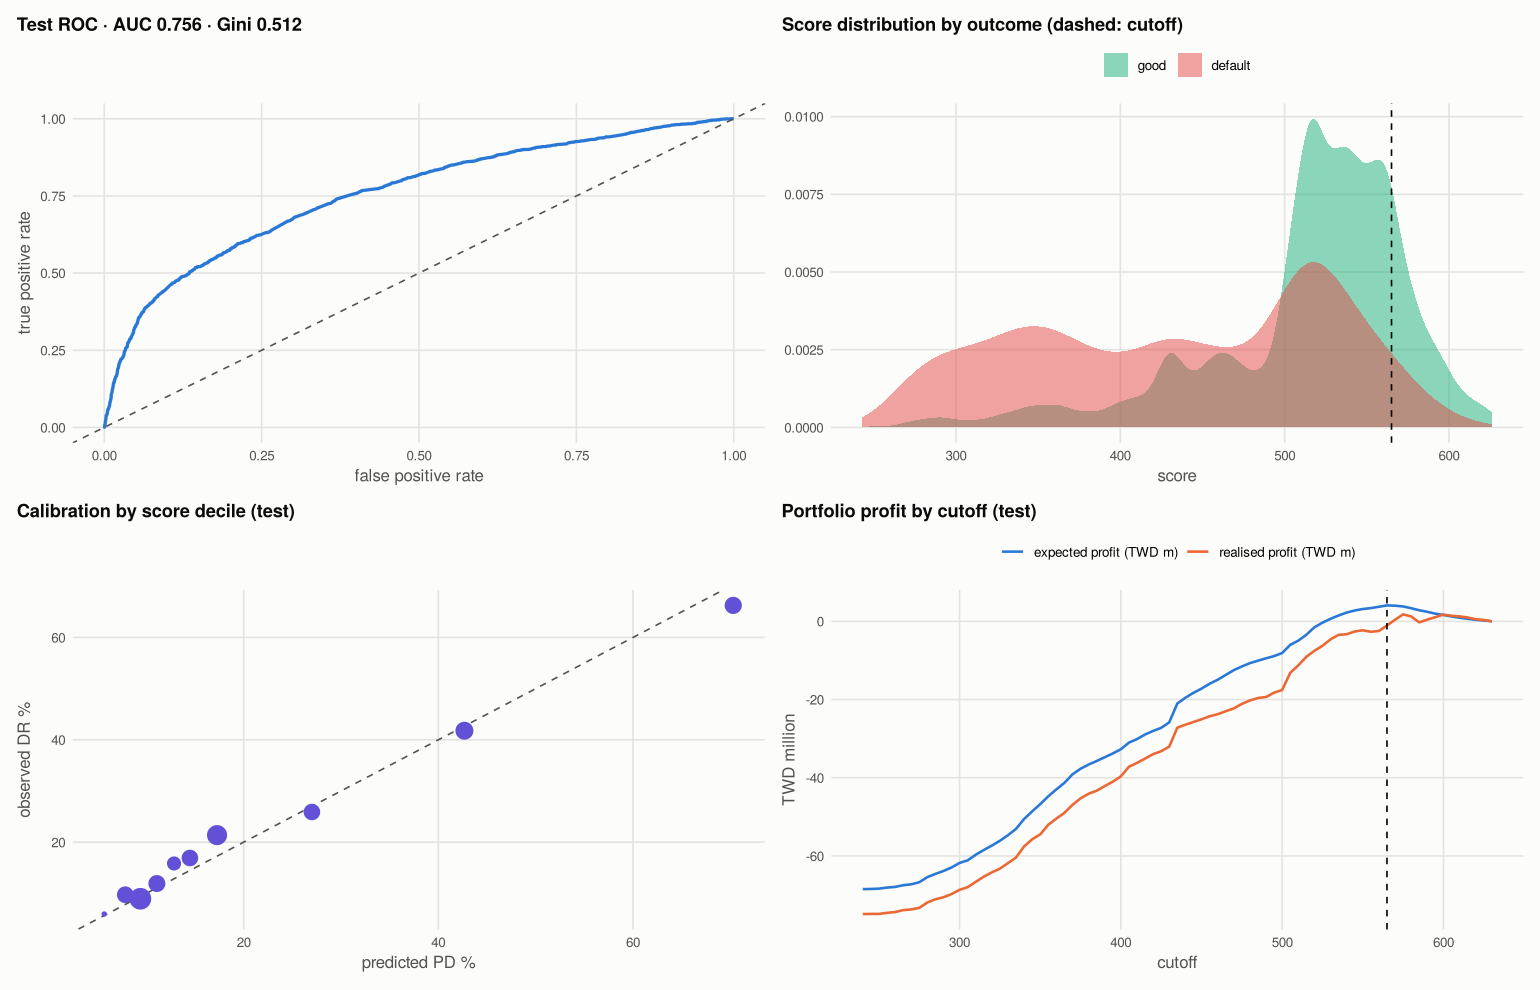

In [8]:
econ <- tibble(score = test_score, pd = test_pd, y = test$default,
               limit = test$LIMIT_BAL,
               ead = pmax(test$BILL_AMT1, 0.5 * test$LIMIT_BAL)) %>%
  arrange(desc(score)) %>%
  mutate(exp_profit = (1 - pd) * MARGIN * limit - pd * LGD * ead,
         real_profit = (1 - y) * MARGIN * limit - y * LGD * ead)
cut_grid <- map_dfr(seq(floor(min(econ$score) / 10) * 10,
                        ceiling(max(econ$score) / 10) * 10, by = 5),
                    function(c) {
  a <- econ %>% filter(score >= c)
  tibble(
    cutoff = c, `approval rate %` = nrow(a) / nrow(econ) * 100,
      `default rate approved %` = mean(a$y) * 100,
    `expected profit (TWD m)` = sum(a$exp_profit) / 1e6,
      `realised profit (TWD m)` = sum(a$real_profit) / 1e6
  )
})
best_cut <- cut_grid %>% slice_max(`expected profit (TWD m)`, n = 1)
cat(sprintf(
  "Profit-maximising cutoff %d points: approves %.0f%% of applicants, default rate among approved %.1f%% (vs %.1f%% overall)\n",
  best_cut$cutoff, best_cut$`approval rate %`,
    best_cut$`default rate approved %`, mean(test$default) * 100
))

# --- Chart 2: ROC, score distributions, calibration and the profit curve
roc_df <- tibble(fpr = 1 - roc_te$specificities, tpr = roc_te$sensitivities)
p_roc <- ggplot(roc_df, aes(fpr, tpr)) +
  geom_line(colour = PALETTE[1], linewidth = 1) +
  geom_abline(linetype = "dashed", colour = INK_2) +
  labs(x = "false positive rate", y = "true positive rate",
       title = sprintf("Test ROC · AUC %.3f · Gini %.3f", auc(roc_te), 2 *
                       auc(roc_te) - 1))
p_dist <- ggplot(tibble(score = test_score,
                        y = factor(test$default, 0:1, c("good", "default"))),
                 aes(score, fill = y)) +
  geom_density(alpha = 0.5, colour = NA) +
  scale_fill_manual(values = c(good = PALETTE[3], default = PALETTE[8])) +
  geom_vline(xintercept = best_cut$cutoff, linetype = "dashed") +
  labs(x = "score", y = NULL,
       title = "Score distribution by outcome (dashed: cutoff)")
p_cal <- ggplot(bands, aes(`predicted PD %`, `observed DR %`)) +
  geom_abline(linetype = "dashed", colour = INK_2) +
  geom_point(aes(size = clients), colour = PALETTE[7]) +
  scale_size(guide = "none") +
  labs(title = "Calibration by score decile (test)")
p_cut <- ggplot(cut_grid %>%
                pivot_longer(c(`expected profit (TWD m)`,
                               `realised profit (TWD m)`)),
                aes(cutoff, value, colour = name)) +
  geom_line(linewidth = 0.8) +
  geom_vline(xintercept = best_cut$cutoff, linetype = "dashed") +
  scale_colour_manual(values = c(PALETTE[1], PALETTE[2])) +
  labs(y = "TWD million", title = "Portfolio profit by cutoff (test)")
fig2 <- (p_roc | p_dist) / (p_cal | p_cut)
save_fig(fig2, "02_validation_and_cutoff", width = 15, height = 9)
options(repr.plot.height = 9); print(fig2); options(repr.plot.height = 5)
write_csv(iv_tab, file.path(OUT_DIR, "information_value.csv"))
write_csv(points_tab, file.path(OUT_DIR, "scorecard_points.csv"))
write_csv(perf, file.path(OUT_DIR, "discrimination.csv"))
write_csv(bands, file.path(OUT_DIR, "calibration_by_decile.csv"))
write_csv(cut_grid, file.path(OUT_DIR, "cutoff_analysis.csv"))
cat("Outputs:", paste(list.files(OUT_DIR), collapse = ", "), "\n")

## 8. Reading the results and limitations

The UCI Taiwan credit-card dataset (30,000 clients, 22.1% default in the following month), 70/30 stratified split:

**The scorecard ranks well for a behavioural card model.** Test AUC is 0.756 (95% CI 0.744–0.769), Gini 0.51 and KS 0.38. The train–test gap is small (Gini 0.56 vs 0.51), and score PSI between train and test is 0.001, so the population is stable. Fourteen WoE variables survive stepwise AIC, all with positive coefficients as a WoE model requires; the largest generalised VIF is 2.8.

**Recent delinquency dominates.** The current repayment status (PAY_1) has an IV of 0.92. It is "suspicious" by the usual 0.5 rule, which in an application scorecard would point to leakage. Here it is a genuine behavioural signal: a client one month late loses 55 points, and two months or more loses 125, the largest swing of any variable.

The repayment amounts and the utilisation ratio come next. Older delinquency adds little once PAY_1 is in (PAY_2's coefficient is not significant). 17 of 25 variables needed manual re-binning to make the WoE monotonic, mostly because the repayment-status codes −2, −1 and 0 all mean "not delinquent".

- **Calibration fails the Hosmer–Lemeshow-style test** (χ² 35.7, p < 0.001) even though deciles look close by eye. The middle bands (scores 482–531) are under-predicted by 2–4 points, and the test default rate (22.6%) is a little above train (21.9%). Before using the PDs for capital or pricing, recalibrate the intercept on the latest default rate. Ranking is unaffected.

**The profit-optimal cutoff is strict because this portfolio is very risky.** With a 4% margin, 75% LGD and EAD of at least half the limit, approving everyone loses about TWD 70–75m on the test set. The best cutoff, 565 points, approves only 14% of clients with a 7.6% default rate among them.

At 22% default this book (from Taiwan's 2005 card crisis) is far riskier than a typical U.S. card portfolio, whose annual charge-off rate is a few percent. The method transfers; the cutoff does not.

**Limitations**

- One snapshot, 2005; no out-of-time sample, so PSI only checks a random split.
- "Default" is a missed payment next month, not the 90-days-past-due definition used for IFRS 9 or Basel.
- The profit economics (margin, LGD, EAD) are illustrative.

## References

### Finance and regulation

- Siddiqi, N. (2017). *Intelligent credit scoring: Building and implementing better credit risk scorecards* (2nd ed.). Wiley. https://doi.org/10.1002/9781119282396
- Thomas, L. C., Crook, J., & Edelman, D. (2017). *Credit scoring and its applications* (2nd ed.). SIAM. https://doi.org/10.1137/1.9781611974560
- Yeh, I.-C., & Lien, C.-H. (2009). The comparisons of data mining techniques for the predictive accuracy of probability of default of credit card clients. *Expert Systems with Applications, 36*(2), 2473–2480. https://doi.org/10.1016/j.eswa.2007.12.020
- Basel Committee on Banking Supervision. (2005). *Studies on the validation of internal rating systems* (Working Paper No. 14). Bank for International Settlements. https://www.bis.org/publ/bcbs_wp14.htm
- Hand, D. J., & Henley, W. E. (1997). Statistical classification methods in consumer credit scoring: A review. *Journal of the Royal Statistical Society: Series A, 160*(3), 523–541. https://doi.org/10.1111/j.1467-985X.1997.00078.x

### Machine learning and deep learning

- Robin, X., Turck, N., Hainard, A., Tiberti, N., Lisacek, F., Sanchez, J.-C., & Müller, M. (2011). pROC: An open-source package for R and S+ to analyze and compare ROC curves. *BMC Bioinformatics, 12*, 77. https://doi.org/10.1186/1471-2105-12-77
- DeLong, E. R., DeLong, D. M., & Clarke-Pearson, D. L. (1988). Comparing the areas under two or more correlated receiver operating characteristic curves: A nonparametric approach. *Biometrics, 44*(3), 837–845. https://doi.org/10.2307/2531595
- Xie, S. (2024). *scorecard: Credit risk scorecard* (R package). CRAN. https://CRAN.R-project.org/package=scorecard
- Akaike, H. (1974). A new look at the statistical model identification. *IEEE Transactions on Automatic Control, 19*(6), 716–723. https://doi.org/10.1109/TAC.1974.1100705